# Multithreading

## How many CPU-cores are there?

**Terminology:** CPU-threads = "virtual cores" = "hardware threads" within physical CPU-cores.

In [87]:
using SysInfo
sysinfo()

Hostname: 	kurs16
CPU(s): 	1 x Intel(R) Core(TM) i5-6440HQ CPU @ 2.60GHz
CPU target: 	skylake

∘ CPU 1: 
	→ 4 cores (4 CPU-threads)
	→ 1 NUMA domain


Note that there may be more than one CPU thread per physical CPU core (e.g. hyperthreading).

### HLRS Training Cluster: Login Node

```julia-repl
Hostname: 	cl7fr1
CPU(s): 	1 x Intel(R) Xeon(R) Gold 6326 CPU @ 2.90GHz
CPU target: 	icelake-server

∘ CPU 1:
	→ 16 cores (32 CPU-threads due to 2-way SMT)
	→ 1 NUMA domain
```

### HLRS Training Cluster: Compute Node (`skl`)

```julia-repl
Hostname:       n001801
CPU(s):         2 x Intel(R) Xeon(R) Gold 6138 CPU @ 2.00GHz
CPU target:     skylake-avx512
Cores:          40 (80 CPU-threads due to 2-way SMT)
NUMA domains:   2 (20 cores each)

∘ CPU 1: 
        → 20 cores (40 CPU-threads due to 2-way SMT)
        → 1 NUMA domain
∘ CPU 2: 
        → 20 cores (40 CPU-threads due to 2-way SMT)
        → 1 NUMA domain
```

### HLRS Training Cluster: GPU Node (`clx-ai`)

```julia-repl
Hostname:       n010301
CPU(s):         2 x Intel(R) Xeon(R) Gold 6240 CPU @ 2.60GHz
CPU target:     cascadelake
Cores:          36 (72 CPU-threads due to 2-way SMT)
NUMA domains:   2 (18 cores each)

∘ CPU 1: 
        → 18 cores (36 CPU-threads due to 2-way SMT)
        → 1 NUMA domain
∘ CPU 2: 
        → 18 cores (36 CPU-threads due to 2-way SMT)
        → 1 NUMA domain

Detected GPUs:  8
```

## What are threads?
Threads are **execution units within a process** that can run simultaneously. While processes are separate, threads run in a **shared memory** space (heap).

<!-- <img src="./imgs/what-are-threads.png" width=500px> -->

<br>
<img src="imgs/stack_heap_threads.svg" width=450px>
<br>

## Starting Julia with multiple threads

By default, Julia starts with a single *user thread*. We must tell it explicitly to start multiple user threads. There are a couple of ways to do this:

* Environment variable: `export JULIA_NUM_THREADS=4`
* Command line argument: `julia --threads 4` or `julia -t 4`

**It is currently not (easily) possible to change the number of threads at runtime!**

For Jupyter, we create another kernel that starts Julia with multiple threads.

In [88]:
using IJulia
installkernel("Julia (4 threads)", "--project=@.", env=Dict("JULIA_NUM_THREADS"=>"4"))

[ Info: Installing 'Julia (4 threads) 1.13' kernelspec in /home/hlrskn16/.local/share/jupyter/kernels/julia-_4-threads_-1.13


"/home/hlrskn16/.local/share/jupyter/kernels/julia-_4-threads_-1.13"

Afterwards, we need to **refresh the page** and select the new `Julia (4 threads) 1.13` kernel in the top right corner. (Restart Jupyter if the kernel doesn't show up.)

We can readily check how many threads we are running:

In [89]:
Threads.nthreads()

4

### User threads vs default threads

Technically, the Julia process is also spawning multiple threads already in "single-threaded" mode, like
* a thread for unix signal listening
* multiple OpenBLAS threads for BLAS/LAPACK operations
* GC threads

We call the threads that we can actually run computations on *user threads* or *Julia threads*.

In [90]:
using LinearAlgebra
BLAS.get_num_threads()

1

## Where are my threads running?

In [91]:
using ThreadPinning

In [92]:
threadinfo()

Hostname: 	kurs16
CPU(s): 	1 x Intel(R) Core(TM) i5-6440HQ CPU @ 2.60GHz
CPU target: 	skylake
Cores: 		4 (4 CPU-threads)
NUMA domains: 	1 (4 cores each)

Julia threads: 	4

CPU socket 1
  0,1,2,3


# = Julia thread, # = >1 Julia thread

(Mapping: 1 => 3, 2 => 1, 3 => 3, 4 => 1,)


## Task-based multithreading

Julia implements **task-based** multithreading. In this paradigm, a task - e.g. a computational piece of a code - is marked for **parallel** execution on **any** of the Julia threads. Julia's **dynamic scheduler** will put the task on a thread and trigger the execution of the task.

<br>
<!-- <img src="imgs/task-based-parallelism.png" width=768px> -->
<img src="imgs/tasks_threads_cores.svg" width=650px>
</br>

Task-based multithreading: **The user should think about tasks and not threads**.
* By default, the user does not control on which thread a task will run (the task might even [migrate](https://docs.julialang.org/en/v1/manual/multi-threading/#man-task-migration) between threads!).

**Advantages:**
* high-level abstraction: one can spawn many tasks (>> number of threads)
* nestable multithreading

**Disadvantages:**
* dynamic scheduling overhead
* uncertainty and potentially suboptimal task → thread assignment
  * can get in the way when performance engineering

### Spawning tasks

In [93]:
using Base.Threads

In [94]:
@spawn 3+3

Task (runnable, started) @0x00007f78e0ab9f00

`@spawn` creates a `Task` and schedules it for execution on an available Julia thread (we don't control which one!).

Note that `Threads.@spawn` is **asynchronous** and **non-blocking**, that is, it doesn't wait for the task to actually run but immediately returns a `Task`.

We can fetch the result of a task with `fetch`.

In [95]:
t = @spawn 3+3
fetch(t)

6

# NOTE: You don't have to wait for this to finish. You can do other stuff with spawn. The fetch command is blocking

While `@spawn` returns right away, `fetch` is **blocking** as it has to wait for the task to actually finish.

In [96]:
@time t = @spawn begin
    sleep(3)
    return 3+3
end
@time fetch(t)

  0.000073 seconds (61 allocations: 3.297 KiB)
  3.000468 seconds (297 allocations: 14.438 KiB)


6

We can use the macro `@sync` to synchronize all (lexically) encompassed asynchronous operations (`@spawn`).

In [97]:
@time @sync t = @spawn begin
    sleep(3)
    return 3+3
end
@time fetch(t)

  3.009678 seconds (12.31 k allocations: 675.078 KiB, 0.27% compilation time)
  0.000004 seconds


6

#### Example: multithreaded `map`

`tmap`: *threaded map*

In [98]:
function tmap(f, collection)
    # for each x ∈ collection, spawn a task to compute f(x)
    tasks = map(collection) do x # this is a syntax to define an anonymous function, e.g. x -> x^2, you can write map(x-> x^2, collection), or you can write map(collection) do x #input arguments# and then the function on the next line
        @spawn f(x)
    end
    # fetch and return all the results
    return fetch.(tasks)
end

tmap (generic function with 1 method)

In [99]:
M = [rand(200,200) for i in 1:8];

In [100]:
using LinearAlgebra: svdvals

In [101]:
tmap(svdvals, M)

8-element Vector{Vector{Float64}}:
 [100.04749855627418, 7.953225474745347, 7.85179849510248, 7.815073662767909, 7.6609360472315124, 7.581703801385899, 7.536650175953792, 7.430130916311901, 7.264047560572464, 7.184457351099263  …  0.2788551306715302, 0.2546450152020893, 0.23083700517164207, 0.21234971631701452, 0.17037531390418462, 0.1479913046650302, 0.08020596833156868, 0.05156829956905607, 0.03858490588487387, 0.017182698721019695]
 [100.54164446319047, 8.024066617666627, 7.875738715355952, 7.705197701788962, 7.5946575212448435, 7.582741371631329, 7.56666917453072, 7.4852920378380645, 7.369794011307792, 7.329173604255888  …  0.28932762273536095, 0.2424887579871243, 0.1822979636658756, 0.16073270177692833, 0.15332215630474677, 0.12803732327244208, 0.09407977751758878, 0.060185313158842756, 0.017478035259629564, 0.007827562682950076]
 [100.54725516138197, 7.903834289520226, 7.864791127460761, 7.85147841093912, 7.7270109112619, 7.625780556362062, 7.555209083164869, 7.436990780374964, 7

In [102]:
using BenchmarkTools

In [103]:
@btime tmap($svdvals, $M) samples=10 evals=3;
@btime map($svdvals, $M) samples=10 evals=3;

  10.389 ms (155 allocations: 3.38 MiB)
  28.503 ms (106 allocations: 3.37 MiB)


If you use multithreading in Julia in combination with BLAS/LAPACK functions, it is important to carefully consider and configure the [interplay between Julia threads and BLAS threads](https://carstenbauer.github.io/ThreadPinning.jl/stable/explanations/blas/).

Easiest way out: turn of BLAS/LAPACK multithreading.

In [104]:
using LinearAlgebra: BLAS
BLAS.set_num_threads(1)

In [105]:
@btime tmap($svdvals, $M) samples=20 evals=10;

  9.904 ms (155 allocations: 3.38 MiB)


#### Example: multithreading for-loops

In [106]:
using OhMyThreads.Tools: taskid

In [107]:
@sync for i in 1:8
    @spawn println("Task ", taskid(), " is running iteration ", i, " on thread ", threadid())
end

Task 14320819431863784016 is running iteration 6 on thread 3
Task 5272563614159259966 is running iteration 7 on thread 5
Task 15727390789967952701 is running iteration 4 on thread 5
Task 12267321388309759590 is running iteration 2 on thread 5
Task 904834809159892621 is running iteration 5 on thread 5
Task 11572117603983147597 is running iteration 8 on thread 5
Task 1233741719066054940 is running iteration 1 on thread 2
Task 13803521821609601409 is running iteration 3 on thread 4


#### Example: nestable multithreading

Recursive Fibonacci series

$$ F(n) = F(n-1) + F(n-2), \qquad F(1) = F(2) = 1$$

(Note: Algorithmically, this is a highly inefficient implementation of the Fibonacci series!)

In [108]:
function fib(n)
    n < 2 && return n
    t = @spawn fib(n-2)
    return fib(n-1) + fetch(t)
end

fib (generic function with 1 method)

We are nesting `@spawn` calls recursively!

In [109]:
fib(20)

6765

In [110]:
tmap(fib, 1:20) # multithreaded tmap applying a multithreaded fib

20-element Vector{Int64}:
    1
    1
    2
    3
    5
    8
   13
   21
   34
   55
   89
  144
  233
  377
  610
  987
 1597
 2584
 4181
 6765

### Load-balancing and chunking

If there are many tasks (e.g. many more than available threads), Julia's scheduler balances the load of these tasks among threads.

In [111]:
using OhMyThreads: chunks, index_chunks

In [112]:
x = rand(10)
collect(chunks(x; n=3)) # chunks hold elements of x (views)

3-element Vector{SubArray{Float64, 1, Vector{Float64}, Tuple{UnitRange{Int64}}, true}}:
 [0.7856354765306893, 0.843927162816159, 0.7479050928416764, 0.34295624971304506]
 [0.5788881708143264, 0.8942266304963424, 0.7454484637100285]
 [0.4678411539793955, 0.1174019737882599, 0.7506670656211863]

In [113]:
collect(index_chunks(x; n=3)) # chunks hold indices of elements of x

3-element Vector{UnitRange{Int64}}:
 1:4
 5:7
 8:10

In [114]:
# this function is purely pedagogical
function tmap_tracking(f, collection; tracker = [UnitRange[] for _ in 1:nthreads()], ntasks=nthreads())
    result = zeros(Float64, length(collection))
    @sync for chunk_indices in index_chunks(collection; n=ntasks)   # chunk up collection into ntasks-many chunks
        @spawn begin                                                # spawn a task for each chunk
            for i in chunk_indices                                  # for each element of a that belongs to this chunk/task
                result[i] = f(collection[i])                        # apply f
            end
            push!(tracker[threadid()-1], chunk_indices)               # keep track of which thread ran the task
        end
    end
    return result, tracker
end

tmap_tracking (generic function with 1 method)

In [115]:
xs = 1:2^7
f(x) = sum(abs2, rand() for _ in 1:(2^14*x)) # computational cost is increasing as a function of x (non-uniform)

f (generic function with 1 method)

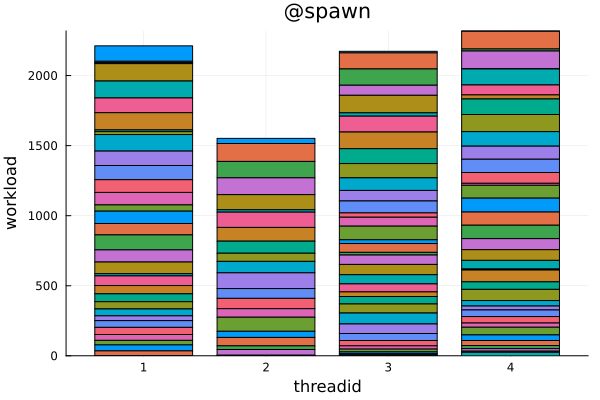

In [116]:
using StatsPlots
using Base.Threads: nthreads

result, tracker = tmap_tracking(f, xs; ntasks=length(xs))   # create a task for each element of `a`
# result, tracker = tmap_tracking(f, xs; ntasks=8*nthreads()) # create 8*nthreads() tasks, each handling a chunk of `a`
# result, tracker = tmap_tracking(f, xs; ntasks=4*nthreads()) # create 4*nthreads() tasks, each handling a chunk of `a`
# result, tracker = tmap_tracking(f, xs; ntasks=2*nthreads()) # create 2*nthreads() tasks, each handling a chunk of `a`
# result, tracker = tmap_tracking(f, xs; ntasks=1)            # create a single task, handling all of `a`
# result, tracker = tmap_tracking(f, xs; ntasks=nthreads())   # create nthreads() tasks, each handling a chunk of `a`

# plotting
thread_workloads = zeros(Int, nthreads(), maximum(length, tracker))
for th in eachindex(tracker)
    for (i, ws) in enumerate(tracker[th])
        thread_workloads[th, i] = sum(ws)
    end
end
b = groupedbar(thread_workloads, xlab="threadid", ylab="workload", title="@spawn", legend=false, bar_position=:stack)
display(b)

#### Multithreading for-loops (revisited): `OhMyThreads.@tasks`

In [117]:
using OhMyThreads: @tasks

In [118]:
@tasks for i in 1:8
    println("Task ", taskid(), " is running iteration ", i, " on thread ", threadid())
end

Task 17417965840597712023 is running iteration 5 on thread 2
Task 17417965840597712023 is running iteration 6 on thread 2
Task 10250298674509091937 is running iteration 7 on thread 3
Task 10250298674509091937 is running iteration 8 on thread 3
Task 363263488993588639 is running iteration 1 on thread 4
Task 10696133060478436091 is running iteration 3 on thread 5
Task 363263488993588639 is running iteration 2 on thread 4
Task 10696133060478436091 is running iteration 4 on thread 5


**The iteration space is divided into `nthreads()` contiguous chunks**, then creates a task for each chunks. $\quad \Rightarrow \quad $ **no load balancing!**

You can tune the number of tasks to spawn (== chunking granularity) for `@tasks` with `@set ntasks = value`.

In [119]:
using OhMyThreads: @set

In [120]:
@tasks for i in 1:8
    @set ntasks = 1 
    println("Task ", taskid(), " is running iteration ", i, " on thread ", threadid())
end

Task 16461488425634487243 is running iteration 1 on thread 1
Task 16461488425634487243 is running iteration 2 on thread 1
Task 16461488425634487243 is running iteration 3 on thread 1
Task 16461488425634487243 is running iteration 4 on thread 1
Task 16461488425634487243 is running iteration 5 on thread 1
Task 16461488425634487243 is running iteration 6 on thread 1
Task 16461488425634487243 is running iteration 7 on thread 1
Task 16461488425634487243 is running iteration 8 on thread 1


In [121]:
@tasks for i in 1:8
    @set ntasks = 8   # same as @sync for .... @spawn ... end
    println("Task ", taskid(), " is running iteration ", i, " on thread ", threadid())
end

Task 16893005755720440229 is running iteration 4 on thread 2
Task 5233273410523039810 is running iteration 5 on thread 4
Task 9314124831244777895 is running iteration 1 on thread 5
Task 14578193533012334178 is running iteration 2 on thread 3
Task 17837729337421438168 is running iteration 7 on thread 4
Task 8966967132115609102 is running iteration 3 on thread 5
Task 889476957877112287 is running iteration 6 on thread 3
Task 16678556730713784700 is running iteration 8 on thread 4


(Note that you can't tune the number of tasks for `Threads.@threads`! 🙁)

## Opting out of dynamic scheduling

For "traditional HPC", where you tell each thread what to do, you might want to opt out of dynamic scheduling and task migration. 

**Advantages:**

* guaranteed task-thread mapping ("task pinning")
* lower overhead

**Disadvantages:**

* often less portable code (e.g. hardcoded assumptions about the system)
* no (or at least bad) nestability

### Spawning a sticky task on a specific thread

In [122]:
using OhMyThreads: @spawnat

In [123]:
@spawnat 4 println("Task ", taskid(), " is running on thread ", threadid(), ", and always will be 😉");

### Static scheduling

* **Statically** map tasks to threads, specifically: task 1 → thread 1, task 2 → thread 2, and so on.

For `@tasks` there is `@set scheduler = :static`.

In [124]:
@tasks for i in 1:2*nthreads()
    @set scheduler = :static
    println("Task ", taskid(), " is running iteration ", i, " on thread ", threadid());
end

Task 10181917437592435161 is running on thread 4, and always will be 😉
Task 14180929527659026322 is running iteration 3 on thread 3
Task 14180929527659026322 is running iteration 4 on thread 3
Task 18179452328710671784 is running iteration 7 on thread 5
Task 18179452328710671784 is running iteration 8 on thread 5
Task 4677515113189670430 is running iteration 1 on thread 2
Task 4677515113189670430 is running iteration 2 on thread 2
Task 2676706714835251088 is running iteration 5 on thread 4
Task 2676706714835251088 is running iteration 6 on thread 4


For `scheduler = :static`, every thread handles precisely two iterations and always the same iterations!

In [125]:
@tasks for i in 1:2*nthreads()
    @set scheduler = :dynamic # :dynamic is the default
    println("Task ", taskid(), " is running iteration ", i, " on thread ", threadid());
end

Task 15447030678998471779 is running iteration 5 on thread 5
Task 8390484581880971077 is running iteration 1 on thread 4
Task 8390484581880971077 is running iteration 2 on thread 4
Task 4377353572699143938 is running iteration 7 on thread 2
Task 4377353572699143938 is running iteration 8 on thread 2
Task 15552843735324920111 is running iteration 3 on thread 3
Task 15552843735324920111 is running iteration 4 on thread 3
Task 15447030678998471779 is running iteration 6 on thread 5


## Beware of Multithreading: Parallel Summation

In [126]:
data = rand(1_000_000 * nthreads());

sum(data) # we want to parallelize this

2.0003771008096803e6

### How you should parallelize it

The real answer is: There is no need to roll your own parallel summation (or your own `tmap` 😉). 

In [127]:
using OhMyThreads: treduce

treduce(+, data)

2.0003771008096803e6

In [128]:
treduce(+, data) ≈ sum(data)

true

But let's assume we want to write a parallel version ourselves.

### Task-focused parallel version

Key questions for task-based parallelisation:
* How to divide the computation into seperate **tasks**?
    * Answer: chunk up the data and perform partial sums.
* How many **tasks** should we create?
    * Answer: since the workload is uniform, `nthreads()` many tasks is a reasonable choice.

In [129]:
function sum_map_spawn(data; ntasks=nthreads())
    ts = map(chunks(data, n=ntasks)) do chunk_elements
        @spawn sum(chunk_elements)
    end
    return sum(fetch.(ts))
end

sum_map_spawn (generic function with 1 method)

* Conceptually simple and task-focused
  * → We're **explicitly** spawning one task per chunk.
  * → No mention of threads, except in `ntasks=nthreads()`.
* In the latter form, we don't even need a manual pre-allocation (it is hidden in the map operation).

In [130]:
sum_map_spawn(data) ≈ sum(data)

true

In [131]:
@btime sum_map_spawn($data);

  1.218 ms (36 allocations: 1.97 KiB)


### Mistake 1: Race condition

In [ ]:
function sum_threads_naive(data)
    s = zero(eltype(data))
    @tasks for i in eachindex(data)
        s += data[i]
    end
    return s
end

In [ ]:
@show sum(data);
@show sum_threads_naive(data);

In [ ]:
using OhMyThreads: @allow_boxed_captures
@allow_boxed_captures @show sum_threads_naive(data);

**Wrong** result! Even worse, it's **non-deterministic** and different every time!

There is a [race condition](https://en.wikipedia.org/wiki/Race_condition) which typically appear when multiple tasks are modifying shared state simultaneously.

→ If possible, **don't modify shared (i.e. non task-local) state!**

### Mistake 2: Thread-focused rather than task-focused

You might be inclined to write something similar to the following (intentionally written in a slightly more verbose form):

In [ ]:
function sum_threads_unsafe(data)
    psums = zeros(eltype(data), nthreads())
    @threads for i in eachindex(data)    # spawn nthreads many tasks
        current_sum = psums[threadid()]  # read
        new_sum = current_sum + data[i]  # "work"
        psums[threadid()] = new_sum      # write
    end
    return sum(psums)
end

Such an approach is generally **unsafe** because Julia's scheduler may **migrate tasks between threads**!
  * For example, a task might start on thread I, is then paused (say, after "work") and migrated to thread J, where it finishes execution.
  * → The output of `threadid()` might change within a task! To be safe, [don't use `threadid()`](https://julialang.org/blog/2023/07/PSA-dont-use-threadid/) at all!
  
It also goes against the idea of task-based multithreading, as we're **thinking about threads rather than tasks**.

(Note that, in spite of the comments above, the `threadid()` pattern will often still work correctly. **You can't rely on it though!**)

In [ ]:
sum_threads_unsafe(data) ≈ sum(data)

### (Performance) Mistake 3: False sharing

In [57]:
function sum_threads_chunks(data; nchunks=nthreads())
    psums = zeros(eltype(data), nchunks)
    @tasks for (c, chunk_elements) in enumerate(chunks(data; n=nchunks)) # spawn nchunks many tasks
        @simd for x in chunk_elements
            psums[c] += x
        end
    end
    return sum(psums)
end

sum_threads_chunks (generic function with 1 method)

In [132]:
sum_threads_chunks(data) ≈ sum(data)

true

In [134]:
@btime sum($data);
@btime sum_threads_chunks($data);

  1.737 ms (0 allocations: 0 bytes)
  1.533 ms (36 allocations: 2.05 KiB)


Safe, but slow?! Why?

##### Performance issue: [False sharing](https://en.wikipedia.org/wiki/False_sharing)

Why does `sum_threads_chunks` above have bad performance? Although argubaly subtle, this is because different tasks mutate shared data (`psums`) in parallel. There is no *logical* sharing: Tasks access different slots of `psums` and there is no data race. However, CPU cores work on the basis of **cache lines** instead of single elements leading to *implicit* sharing of cache lines.

**Despite its subtlety, false sharing can lead to dramatic slowdown!**

In [ ]:
using CpuId

In [ ]:
cachelinesize() ÷ sizeof(Float64)

<img src="imgs/false_sharing.svg" width=850px>

Different tasks modify the same cache line
* need for synchronization to ensure cache coherency
* performance decreases (dramatically).

Once agin: **The less you modify shared (i.e. non task-local) state, the better!**

##### "Fixed" version

In [80]:
function sum_threads_chunks_local(data; nchunks=nthreads())
    psums = zeros(eltype(data), nchunks)
    @tasks for (c, chunk_elements) in enumerate(chunks(data; n=nchunks))  # spawn nchunks many tasks
        psums[c] = sum(chunk_elements)
    end
    return sum(psums)
end

sum_threads_chunks_local (generic function with 1 method)

* each task/iteration computes a local sum independently
* no *frequent* non-local mutation

In [139]:
sum(data) ≈ sum_threads_chunks_local(data)

true

In [ ]:
@btime sum($data);
@btime sum_threads_chunks_local($data);

## Additional comments

### Synchronization/communication of tasks

Low-level to high-level (roughly):

* [atomic operations](https://docs.julialang.org/en/v1/base/multi-threading/#Atomic-operations)
* [locks](https://docs.julialang.org/en/v1/base/parallel/#Base.ReentrantLock)
* [channels](https://docs.julialang.org/en/v1/base/parallel/#Channels)

Generally, one should try to minimize synchronization/communication as much as possible as it can lead to serialization (or worse).

In [ ]:
d = Dict()
lck = ReentrantLock()
@tasks for i in 1:1000
    @lock lck d[i] = i
end
d

### Garbage collection

If it gets triggered, it stops the world (all threads) for clearing up memory.

Hence, when using multithreading, it is even more important to **avoid heap allocations!**

(If you can't avoid allocations, consider using multiprocessing instead.)

### Pinning Julia threads to CPU threads/cores

A compute node has a complex topology (two sockets, multiple memory channels/domains). Placing the Julia threads systematically on CPU-threads matters for

* the computation performance of your Julia codes
* fluctuations/noises in benchmarks
* hardware-level performance monitoring

#### ThreadPinning.jl

`pinthreads(strategy)`
* `:cputhreads` pin to CPU threads (incl. "hypterthreads") one after another
* `:cores:` pin to CPU cores one after another
* `:numa:` round-robin between NUMA domains
* `:sockets:` round-robin between sockets
* `:affinitymask`: according to an external affinity mask (e.g. set by SLURM)

In [135]:
threadinfo()

Hostname: 	kurs16
CPU(s): 	1 x Intel(R) Core(TM) i5-6440HQ CPU @ 2.60GHz
CPU target: 	skylake
Cores: 		4 (4 CPU-threads)
NUMA domains: 	1 (4 cores each)

Julia threads: 	4

CPU socket 1
  0,1,2,3


# = Julia thread, # = >1 Julia thread

(Mapping: 1 => 1, 2 => 2, 3 => 1, 4 => 2,)


In [138]:
pinthreads(:cores)
threadinfo()

Hostname: 	kurs16
CPU(s): 	1 x Intel(R) Core(TM) i5-6440HQ CPU @ 2.60GHz
CPU target: 	skylake
Cores: 		4 (4 CPU-threads)
NUMA domains: 	1 (4 cores each)

Julia threads: 	4

CPU socket 1
  0,1,2,3


# = Julia thread, # = >1 Julia thread

(Mapping: 1 => 0, 2 => 1, 3 => 2, 4 => 3,)


We'll explore the effect of thread pinning on performance in more detail later → **daxpy_cpu exercise**